## Membaca CSV

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

CSV_PATH = Path("raw_dataset.csv")
df = pd.read_csv(CSV_PATH)

print("Jumlah baris:", len(df))
print("Kolom:", df.columns.tolist())

display(df.head())

Jumlah baris: 91
Kolom: ['experiment_id', 'packet_size_bytes', 'target_rate', 'condition', 'repeat', 'source', 'iperf_status', 'receiver_status', 'throughput_mbps', 'jitter_ms', 'packet_loss_percent', 'latency_ms', 'cpu_client_percent', 'cpu_server_percent', 'cpu_client_samples', 'cpu_server_samples', 'notes']


,experiment_id,packet_size_bytes,target_rate,condition,repeat,source,iperf_status,receiver_status,throughput_mbps,jitter_ms,packet_loss_percent,latency_ms,cpu_client_percent,cpu_server_percent,cpu_client_samples,cpu_server_samples,notes
0,3_128bytes_10mbps_BASELINE_repeat1,128,10M,BASELINE,1,original,0,0,8.00,0.170,0.0,1.4513,89.7606,51.5771,33,35,NaN
1,3_128bytes_10mbps_BASELINE_repeat2,128,10M,BASELINE,2,original,0,0,7.84,0.167,0.0,1.3673,89.1848,51.5143,33,35,NaN
2,3_128bytes_10mbps_BASELINE_repeat3,128,10M,BASELINE,3,original,0,0,7.61,0.196,0.0,1.4150,86.9333,51.0771,33,35,NaN
3,3_128bytes_10mbps_BASELINE_repeat4,128,10M,BASELINE,4,original,0,0,7.89,0.234,0.0,1.3958,88.0636,51.6371,33,35,NaN
4,3_128bytes_10mbps_BASELINE_repeat5,128,10M,BASELINE,5,original,0,0,7.80,0.160,0.0,1.3904,88.4273,51.5771,33,35,NaN


## Memeriksa Status Pengujian dan Nilai Kosong

In [2]:
metrics = [
    "throughput_mbps",
    "latency_ms",
    "jitter_ms",
    "packet_loss_percent",
    "cpu_client_percent",
    "cpu_server_percent",
]

# Pastikan kolom tersedia
print("Kolom metrik yang tersedia:")
print([col for col in metrics if col in df.columns])

# Periksa status pengujian
print("\nStatus iperf3:")
print(df["iperf_status"].value_counts(dropna=False))

print("\nStatus receiver:")
print(df["receiver_status"].value_counts(dropna=False))

# Periksa sumber data
print("\nSumber data:")
print(df["source"].value_counts(dropna=False))

# Periksa nilai kosong 
print("\nJumlah nilai kosong:")
print(df[metrics].isna().sum())

Kolom metrik yang tersedia:
['throughput_mbps', 'latency_ms', 'jitter_ms', 'packet_loss_percent', 'cpu_client_percent', 'cpu_server_percent']

Status iperf3:
iperf_status
0    90
1     1
Name: count, dtype: int64

Status receiver:
receiver_status
0    90
1     1
Name: count, dtype: int64

Sumber data:
source
original    90
retest       1
Name: count, dtype: int64

Jumlah nilai kosong:
throughput_mbps        1
latency_ms             0
jitter_ms              1
packet_loss_percent    1
cpu_client_percent     0
cpu_server_percent     0
dtype: int64


## Data Valid

In [3]:
# Tentukan metrik utama yang wajib tersedia
metrics = [
    "throughput_mbps",
    "latency_ms",
    "jitter_ms",
    "packet_loss_percent",
    "cpu_client_percent",
    "cpu_server_percent",
]

# Data valid harus memiliki status iperf3 dan receiver berhasil
# serta semua metrik utama tersedia
valid_mask = (
    df["iperf_status"].eq(0)
    & df["receiver_status"].eq(0)
    & df[metrics].notna().all(axis=1)
)

df_valid = df.loc[valid_mask].copy()

print("Total data mentah:", len(df))
print("Data valid:", len(df_valid))
print("Data dikecualikan:", len(df) - len(df_valid))

print("\nData valid berdasarkan kondisi:")
print(df_valid.groupby(["condition", "source"]).size())

print("\nData yang dikecualikan:")
display(df.loc[~valid_mask])

Total data mentah: 91
Data valid: 90
Data dikecualikan: 1

Data valid berdasarkan kondisi:
condition  source  
BASELINE   original    44
           retest       1
WIREGUARD  original    45
dtype: int64

Data yang dikecualikan:


,experiment_id,packet_size_bytes,target_rate,condition,repeat,source,iperf_status,receiver_status,throughput_mbps,jitter_ms,packet_loss_percent,latency_ms,cpu_client_percent,cpu_server_percent,cpu_client_samples,cpu_server_samples,notes
64,3_1024bytes_10mbps_BASELINE_repeat5,1024,10M,BASELINE,5,original,1,1,NaN,NaN,NaN,1.5159,19.0727,17.46,33,35,iperf3 status missing/failed; receiver missing...


## Deskripsi Statistik

In [4]:
# Kolom untuk pengelompokan
group_cols = [
    "packet_size_bytes",
    "target_rate",
    "condition",
]

# Metrik yang dianalisis
metrics = [
    "throughput_mbps",
    "latency_ms",
    "jitter_ms",
    "packet_loss_percent",
    "cpu_client_percent",
    "cpu_server_percent",
]

# Hitung mean dan standar deviasi sampel
summary = (
    df_valid
    .groupby(group_cols)[metrics]
    .agg(["mean", "std"])
    .round(4)
)

display(summary)

throughput_mbps          latency_ms  \
                                                   mean      std       mean   
packet_size_bytes target_rate condition                                       
128               100M        BASELINE            7.668   0.4905     1.2907   
                              WIREGUARD           4.278   0.2235    94.3631   
                  10M         BASELINE            7.828   0.1431     1.4040   
                              WIREGUARD           4.272   0.1062    96.1429   
                  50M         BASELINE            8.058   0.1865     1.4242   
                              WIREGUARD           1.222   0.0045   318.0010   
512               100M        BASELINE           32.480   0.3033     1.3560   
                              WIREGUARD           4.784   0.0329   326.2288   
                  10M         BASELINE            9.706   0.2060     1.8962   
                              WIREGUARD           4.862   0.0492   319.1124   
                  50M         BASELINE           27.596  11.5309     1.3256   
                              WIREGUARD          16.800   0.5099    97.3645   
1024              100M        BASELINE           59.280   4.5019     1.3653   
                              WIREGUARD          34.000   1.1203    55.1219   
                  10M         BASELINE            9.976   0.0261     1.4416   
                              WIREGUARD           9.970   0.0224     3.2508   
                  50M         BASELINE           46.700   2.0964     1.4450   
                              WIREGUARD           9.744   0.1276   179.0344   

                                                jitter_ms           \
                                            std      mean      std   
packet_size_bytes target_rate condition                              
128               100M        BASELINE   0.0355    0.1732   0.0116   
                              WIREGUARD  5.1461   29.3198  25.1093   
                  10M         BASELINE   0.0315    0.1854   0.0304   
                              WIREGUARD  3.7383   11.7608  12.3453   
                  50M         BASELINE   0.2063    0.2200   0.0394   
                              WIREGUARD  1.7068    0.6292   0.0641   
512               100M        BASELINE   0.0665    0.1650   0.0087   
                              WIREGUARD  2.1092    0.6810   0.0982   
                  10M         BASELINE   1.2205    0.2816   0.0355   
                              WIREGUARD  3.6809    0.7332   0.1100   
                  50M         BASELINE   0.0442    0.2970   0.1915   
                              WIREGUARD  2.1856   19.3424  25.9220   
1024              100M        BASELINE   0.0569    0.2452   0.0908   
                              WIREGUARD  2.3092   17.3770  26.6291   
                  10M         BASELINE   0.1707    0.3196   0.1469   
                              WIREGUARD  0.1596    0.5714   0.1316   
                  50M         BASELINE   0.1359    0.2276   0.0524   
                              WIREGUARD  2.7819    0.6492   0.0728   

                                        packet_loss_percent          \
                                                       mean     std   
packet_size_bytes target_rate condition                               
128               100M        BASELINE               0.0000  0.0000   
                              WIREGUARD              0.0000  0.0000   
                  10M         BASELINE               0.0000  0.0000   
                              WIREGUARD              0.0000  0.0000   
                  50M         BASELINE               0.0000  0.0000   
                              WIREGUARD              0.0000  0.0000   
512               100M        BASELINE               0.0000  0.0000   
                              WIREGUARD              0.0000  0.0000   
                  10M         BASELINE               0.0003  0.0006   
                              WIREGUARD              0.00

## Tabel Statistik

In [5]:
# Buat tabel statistik 
summary = (
    df_valid
    .groupby(
        ["packet_size_bytes", "target_rate", "condition"]
    )[metrics]
    .agg(["mean", "std"])
    .round(4)
)

# Mengubah MultiIndex kolom menjadi nama biasa
summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary.columns
]

summary = summary.reset_index()

display(summary)

,packet_size_bytes,target_rate,condition,throughput_mbps_mean,throughput_mbps_std,latency_ms_mean,latency_ms_std,jitter_ms_mean,jitter_ms_std,packet_loss_percent_mean,packet_loss_percent_std,cpu_client_percent_mean,cpu_client_percent_std,cpu_server_percent_mean,cpu_server_percent_std
0,128,100M,BASELINE,7.668,0.4905,1.2907,0.0355,0.1732,0.0116,0.0000,0.0000,86.7909,3.3536,50.6486,0.5025
1,128,100M,WIREGUARD,4.278,0.2235,94.3631,5.1461,29.3198,25.1093,0.0000,0.0000,88.4854,0.4371,50.7594,1.0364
2,128,10M,BASELINE,7.828,0.1431,1.4040,0.0315,0.1854,0.0304,0.0000,0.0000,88.4739,1.0845,51.4765,0.2275
3,128,10M,WIREGUARD,4.272,0.1062,96.1429,3.7383,11.7608,12.3453,0.0000,0.0000,88.5315,0.3699,51.1692,0.6605
4,128,50M,BASELINE,8.058,0.1865,1.4242,0.2063,0.2200,0.0394,0.0000,0.0000,89.5279,0.2801,51.1000,0.4231
5,128,50M,WIREGUARD,1.222,0.0045,318.0010,1.7068,0.6292,0.0641,0.0000,0.0000,65.9843,0.9566,39.3257,0.8898
6,512,100M,BASELINE,32.480,0.3033,1.3560,0.0665,0.1650,0.0087,0.0000,0.0000,89.6036,0.1531,51.1594,0.2174
7,512,100M,WIREGUARD,4.784,0.0329,326.2288,2.1092,0.6810,0.0982,0.0000,0.0000,64.4885,1.0108,39.2926,0.6830
8,512,10M,BASELINE,9.706,0.2060,1.8962,1.2205,0.2816,0.0355,0.0003,0.0006,51.9352,0.7422,45.0629,1.0561
9,512,10M,WIREGUARD,4.862,0.0492,319.1124,3.6809,0.7332,0.1100,0.0000,0.0000,65.6988,0.8673,39.4177,0.2428


## Persentase Perubahan

In [6]:
# Ambil rata-rata tiap kondisi
comparison = (
    df_valid
    .groupby(["packet_size_bytes", "target_rate", "condition"])[metrics]
    .mean()
    .reset_index()
)

# Memisahkan Baseline dan WireGuard
baseline = (
    comparison[comparison["condition"] == "BASELINE"]
    .drop(columns="condition")
    .set_index(["packet_size_bytes", "target_rate"])
)

wireguard = (
    comparison[comparison["condition"] == "WIREGUARD"]
    .drop(columns="condition")
    .set_index(["packet_size_bytes", "target_rate"])
)

# Menghitung persentase perubahan terhadap Baseline
percent_change = (
    (wireguard - baseline) / baseline.abs()
) * 100

percent_change = percent_change.reset_index()

display(percent_change.round(2))

,packet_size_bytes,target_rate,throughput_mbps,latency_ms,jitter_ms,packet_loss_percent,cpu_client_percent,cpu_server_percent
0,128,100M,-44.21,7211.11,16828.29,NaN,1.95,0.22
1,128,10M,-45.43,6747.98,6243.47,NaN,0.07,-0.60
2,128,50M,-84.83,22229.02,186.00,NaN,-26.30,-23.04
3,512,100M,-85.27,23958.17,312.73,NaN,-28.03,-23.20
4,512,10M,-49.91,16728.69,160.37,-100.0,26.50,-12.53
5,512,50M,-39.12,7244.83,6412.59,NaN,9.05,1.31
6,1024,100M,-42.65,3937.41,6986.87,NaN,2.30,0.86
7,1024,10M,-0.06,125.49,78.79,NaN,30.86,-9.43
8,1024,50M,-79.13,12289.76,185.24,NaN,-13.67,-19.82


## Throughput

In [8]:
# Rata-rata throughput untuk setiap skenario
throughput_comparison = (
    df_valid
    .groupby(["packet_size_bytes", "target_rate", "condition"])
    ["throughput_mbps"]
    .mean()
    .unstack("condition")
    .reset_index()
)

# Selisih absolut: WireGuard - Baseline
throughput_comparison["diff_mbps"] = (
    throughput_comparison["WIREGUARD"]
    - throughput_comparison["BASELINE"]
)

# Persentase perubahan terhadap Baseline
throughput_comparison["change_percent"] = (
    throughput_comparison["diff_mbps"]
    / throughput_comparison["BASELINE"].abs()
    * 100
)

display(throughput_comparison.round(2))

condition,packet_size_bytes,target_rate,BASELINE,WIREGUARD,diff_mbps,change_percent
0,128,100M,7.67,4.28,-3.39,-44.21
1,128,10M,7.83,4.27,-3.56,-45.43
2,128,50M,8.06,1.22,-6.84,-84.83
3,512,100M,32.48,4.78,-27.70,-85.27
4,512,10M,9.71,4.86,-4.84,-49.91
5,512,50M,27.60,16.80,-10.80,-39.12
6,1024,100M,59.28,34.00,-25.28,-42.65
7,1024,10M,9.98,9.97,-0.01,-0.06
8,1024,50M,46.70,9.74,-36.96,-79.13


In [9]:
throughput_stats = (
    df_valid
    .groupby(
        ["packet_size_bytes", "target_rate", "condition"]
    )["throughput_mbps"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
    .reset_index()
)

display(throughput_stats)

,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,7.668,0.4905,6.94,8.09
1,128,100M,WIREGUARD,5,4.278,0.2235,4.04,4.54
2,128,10M,BASELINE,5,7.828,0.1431,7.61,8.00
3,128,10M,WIREGUARD,5,4.272,0.1062,4.16,4.39
4,128,50M,BASELINE,5,8.058,0.1865,7.82,8.27
5,128,50M,WIREGUARD,5,1.222,0.0045,1.22,1.23
6,512,100M,BASELINE,5,32.480,0.3033,32.00,32.80
7,512,100M,WIREGUARD,5,4.784,0.0329,4.76,4.82
8,512,10M,BASELINE,5,9.706,0.2060,9.41,9.93
9,512,10M,WIREGUARD,5,4.862,0.0492,4.78,4.90


In [10]:
display(
    df_valid.loc[
        (df_valid["packet_size_bytes"] == 512)
        & (df_valid["target_rate"] == "50M")
        & (df_valid["condition"] == "BASELINE"),
        [
            "experiment_id",
            "repeat",
            "source",
            "throughput_mbps",
            "latency_ms",
            "jitter_ms",
            "packet_loss_percent",
            "iperf_status",
            "receiver_status",
            "notes",
        ],
    ].sort_values(["repeat", "source"])
)

,experiment_id,repeat,source,throughput_mbps,latency_ms,jitter_ms,packet_loss_percent,iperf_status,receiver_status,notes
40,3_512bytes_50mbps_BASELINE_repeat1,1,original,6.98,1.3689,0.285,0.0,0,0,NaN
41,3_512bytes_50mbps_BASELINE_repeat2,2,original,33.10,1.2666,0.187,0.0,0,0,NaN
42,3_512bytes_50mbps_BASELINE_repeat3,3,original,32.60,1.3705,0.631,0.0,0,0,NaN
43,3_512bytes_50mbps_BASELINE_repeat4,4,original,33.10,1.3085,0.205,0.0,0,0,NaN
44,3_512bytes_50mbps_BASELINE_repeat5,5,original,32.20,1.3136,0.177,0.0,0,0,NaN


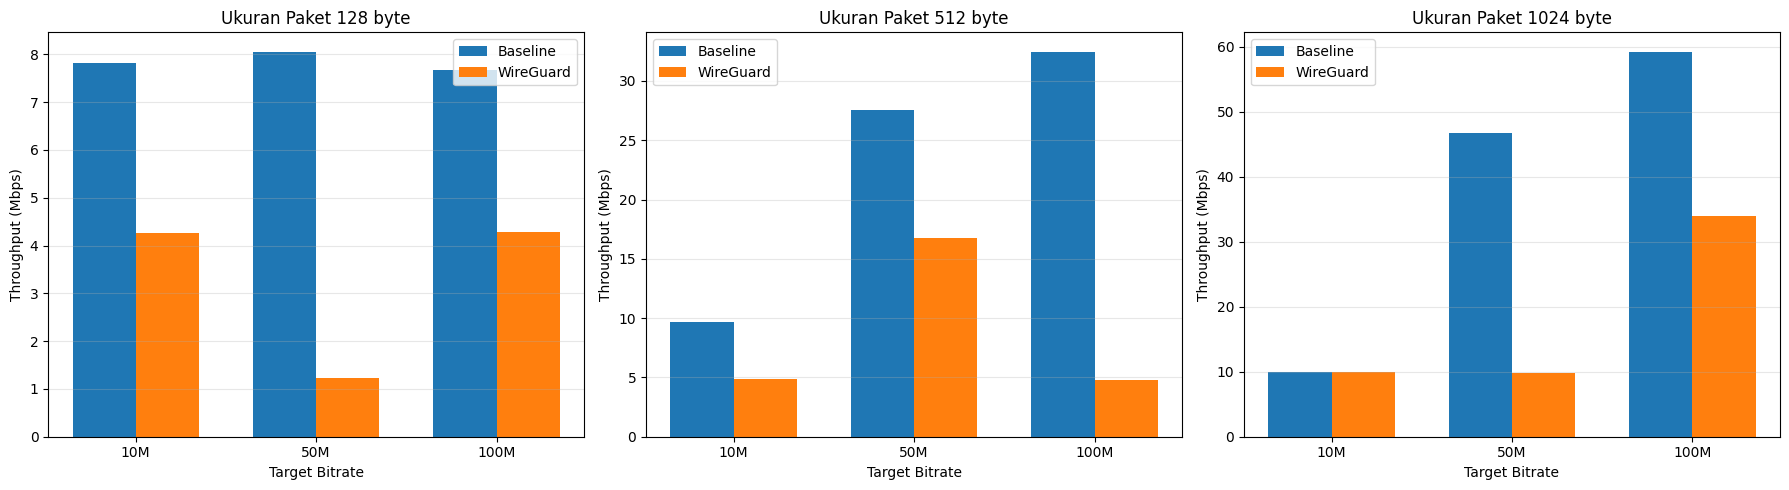

In [12]:
for size in packet_sizes:
    data = throughput_comparison[throughput_comparison["packet_size_bytes"] == size].copy()
    data = data.sort_values("target_rate", key=lambda col: col.map(rate_order))
    x = list(range(len(data)))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 7) if "Throughput" != "Packet Loss" else (12, 9))
    bars_baseline = ax.bar([i - width / 2 for i in x], data["BASELINE"], width, label="Baseline")
    bars_wireguard = ax.bar([i + width / 2 for i in x], data["WIREGUARD"], width, label="WireGuard")
    ax.bar_label(bars_baseline, fmt="%.2f", padding=3, fontsize=8)
    ax.bar_label(bars_wireguard, fmt="%.2f", padding=3, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(data["target_rate"])
    ax.set_title(f"Throughput - Ukuran Paket {size} byte")
    ax.set_xlabel("Target Bitrate")
    ax.set_ylabel("Throughput (Mbps)")
    ax.margins(y=0.22)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
# Grafik fokus: hubungan throughput dengan trafik dan ukuran paket.

fig, ax = plt.subplots(figsize=(12, 7))
for size in packet_sizes:
    data = throughput_comparison[throughput_comparison["packet_size_bytes"] == size].copy()
    data = data.sort_values("target_rate", key=lambda col: col.map(rate_order))
    ax.plot(data["target_rate"], data["BASELINE"], marker="o", label=f"Baseline, {size} byte")
    ax.plot(data["target_rate"], data["WIREGUARD"], marker="s", linestyle="--", label=f"WireGuard, {size} byte")
ax.set_title("Throughput berdasarkan Target Bitrate saja")
ax.set_xlabel("Target Bitrate")
ax.set_ylabel("Throughput (Mbps)")
ax.legend(ncol=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 7))
for rate in sorted(throughput_comparison["target_rate"].dropna().unique(), key=lambda value: rate_order[value]):
    data = throughput_comparison[throughput_comparison["target_rate"] == rate].sort_values("packet_size_bytes")
    ax.plot(data["packet_size_bytes"], data["BASELINE"], marker="o", label=f"Baseline, {rate}")
    ax.plot(data["packet_size_bytes"], data["WIREGUARD"], marker="s", linestyle="--", label=f"WireGuard, {rate}")
ax.set_title("Throughput berdasarkan Ukuran Paket saja")
ax.set_xlabel("Ukuran Paket (byte)")
ax.set_ylabel("Throughput (Mbps)")
ax.legend(ncol=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Latency

In [13]:
latency_stats = (
    df_valid
    .groupby(
        ["packet_size_bytes", "target_rate", "condition"]
    )["latency_ms"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
    .reset_index()
)

display(latency_stats)

,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,1.2907,0.0355,1.2349,1.3182
1,128,100M,WIREGUARD,5,94.3631,5.1461,88.8168,100.7196
2,128,10M,BASELINE,5,1.4040,0.0315,1.3673,1.4513
3,128,10M,WIREGUARD,5,96.1429,3.7383,91.2829,101.4815
4,128,50M,BASELINE,5,1.4242,0.2063,1.2491,1.7081
5,128,50M,WIREGUARD,5,318.0010,1.7068,315.9483,320.2600
6,512,100M,BASELINE,5,1.3560,0.0665,1.2808,1.4293
7,512,100M,WIREGUARD,5,326.2288,2.1092,322.9327,328.0986
8,512,10M,BASELINE,5,1.8962,1.2205,1.2837,4.0769
9,512,10M,WIREGUARD,5,319.1124,3.6809,316.2670,325.2692


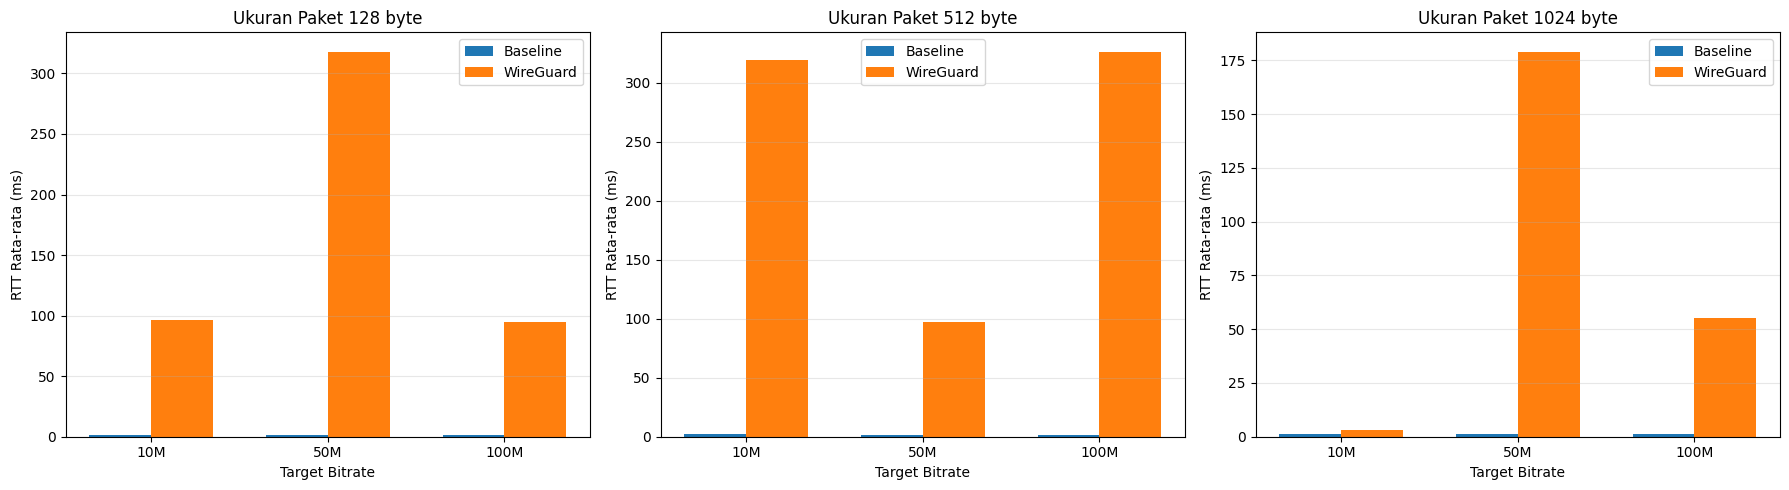

In [16]:
for size in packet_sizes:
    data = latency_comparison[latency_comparison["packet_size_bytes"] == size].copy()
    data = data.sort_values("target_rate", key=lambda col: col.map(rate_order))
    x = list(range(len(data)))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 7) if "Latency" != "Packet Loss" else (12, 9))
    bars_baseline = ax.bar([i - width / 2 for i in x], data["BASELINE"], width, label="Baseline")
    bars_wireguard = ax.bar([i + width / 2 for i in x], data["WIREGUARD"], width, label="WireGuard")
    ax.bar_label(bars_baseline, fmt="%.2f", padding=3, fontsize=8)
    ax.bar_label(bars_wireguard, fmt="%.2f", padding=3, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(data["target_rate"])
    ax.set_title(f"Latency - Ukuran Paket {size} byte")
    ax.set_xlabel("Target Bitrate")
    ax.set_ylabel("RTT Rata-rata (ms)")
    ax.margins(y=0.22)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


## Jitter

In [14]:
jitter_stats = (
    df_valid
    .groupby(
        ["packet_size_bytes", "target_rate", "condition"]
    )["jitter_ms"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
    .reset_index()
)

display(jitter_stats)

,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,0.1732,0.0116,0.161,0.186
1,128,100M,WIREGUARD,5,29.3198,25.1093,0.312,56.754
2,128,10M,BASELINE,5,0.1854,0.0304,0.160,0.234
3,128,10M,WIREGUARD,5,11.7608,12.3453,0.144,28.591
4,128,50M,BASELINE,5,0.2200,0.0394,0.177,0.282
5,128,50M,WIREGUARD,5,0.6292,0.0641,0.527,0.689
6,512,100M,BASELINE,5,0.1650,0.0087,0.151,0.174
7,512,100M,WIREGUARD,5,0.6810,0.0982,0.548,0.803
8,512,10M,BASELINE,5,0.2816,0.0355,0.242,0.332
9,512,10M,WIREGUARD,5,0.7332,0.1100,0.585,0.872


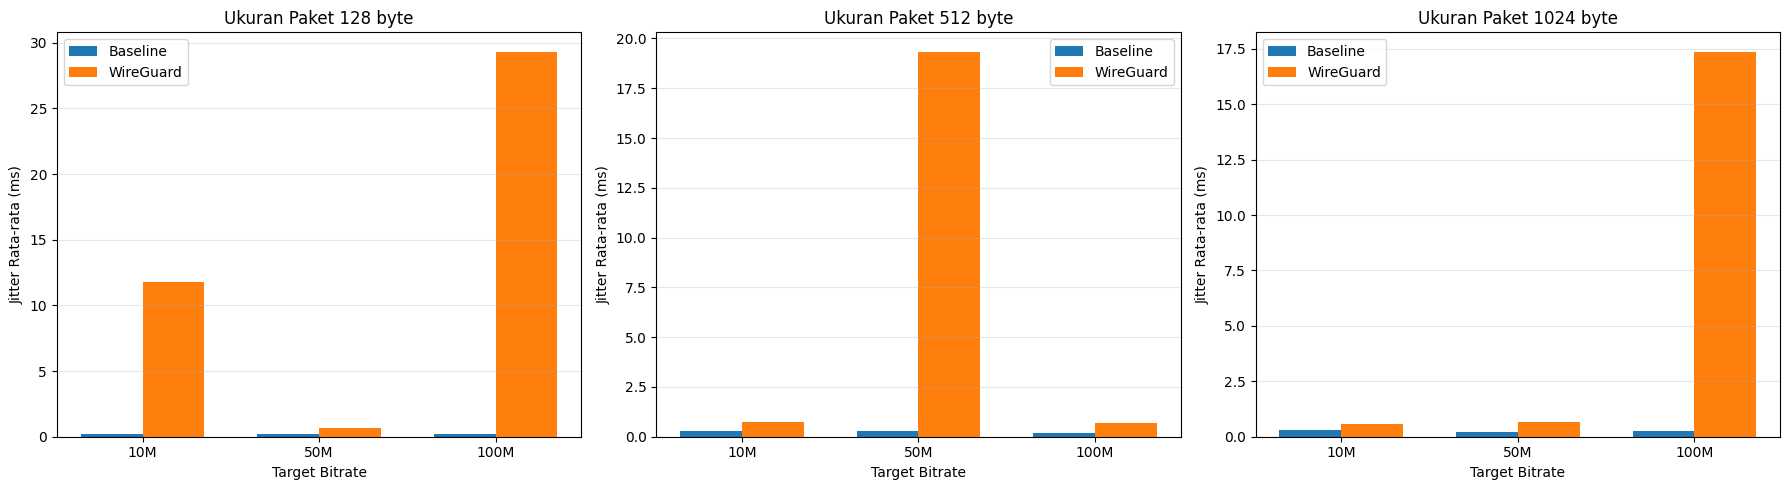

In [17]:
for size in packet_sizes:
    data = jitter_comparison[jitter_comparison["packet_size_bytes"] == size].copy()
    data = data.sort_values("target_rate", key=lambda col: col.map(rate_order))
    x = list(range(len(data)))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 7) if "Jitter" != "Packet Loss" else (12, 9))
    bars_baseline = ax.bar([i - width / 2 for i in x], data["BASELINE"], width, label="Baseline")
    bars_wireguard = ax.bar([i + width / 2 for i in x], data["WIREGUARD"], width, label="WireGuard")
    ax.bar_label(bars_baseline, fmt="%.2f", padding=3, fontsize=8)
    ax.bar_label(bars_wireguard, fmt="%.2f", padding=3, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(data["target_rate"])
    ax.set_title(f"Jitter - Ukuran Paket {size} byte")
    ax.set_xlabel("Target Bitrate")
    ax.set_ylabel("Jitter Rata-rata (ms)")
    ax.margins(y=0.22)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


## Packet Loss

In [18]:
packet_loss_stats = (
    df_valid
    .groupby(
        ["packet_size_bytes", "target_rate", "condition"]
    )["packet_loss_percent"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
    .reset_index()
)

display(packet_loss_stats)

,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,0.0000,0.0000,0.0,0.0000
1,128,100M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
2,128,10M,BASELINE,5,0.0000,0.0000,0.0,0.0000
3,128,10M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
4,128,50M,BASELINE,5,0.0000,0.0000,0.0,0.0000
5,128,50M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
6,512,100M,BASELINE,5,0.0000,0.0000,0.0,0.0000
7,512,100M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
8,512,10M,BASELINE,5,0.0003,0.0006,0.0,0.0014
9,512,10M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000


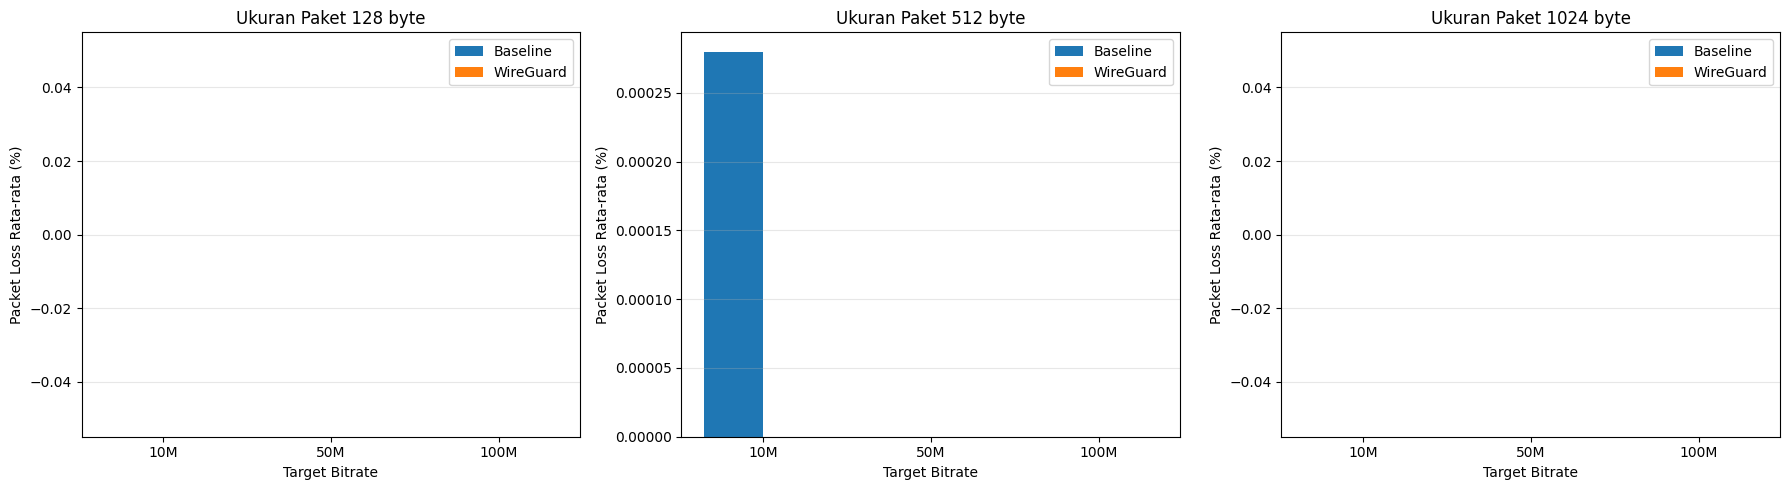

In [19]:
for size in packet_sizes:
    data = packet_loss_comparison[packet_loss_comparison["packet_size_bytes"] == size].copy()
    data = data.sort_values("target_rate", key=lambda col: col.map(rate_order))
    x = list(range(len(data)))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 7) if "Packet Loss" != "Packet Loss" else (14, 9))
    bars_baseline = ax.bar([i - width / 2 for i in x], data["BASELINE"], width, label="Baseline")
    bars_wireguard = ax.bar([i + width / 2 for i in x], data["WIREGUARD"], width, label="WireGuard")
    ax.bar_label(bars_baseline, fmt="%.2f", padding=3, fontsize=10)
    ax.bar_label(bars_wireguard, fmt="%.2f", padding=3, fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(data["target_rate"])
    ax.set_title(f"Packet Loss - Ukuran Paket {size} byte")
    ax.set_xlabel("Target Bitrate")
    ax.set_ylabel("Packet Loss Rata-rata (%)")
    ax.margins(y=0.22)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


## CPU Statistik

In [20]:
cpu_metrics = ["cpu_client_percent", "cpu_server_percent"]

cpu_stats = (
    df_valid
    .groupby(
        ["packet_size_bytes", "target_rate", "condition"]
    )[cpu_metrics]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
)

cpu_stats.columns = [
    f"{metric}_{stat}"
    for metric, stat in cpu_stats.columns
]

display(cpu_stats.reset_index())

,packet_size_bytes,target_rate,condition,cpu_client_percent_count,cpu_client_percent_mean,cpu_client_percent_std,cpu_client_percent_min,cpu_client_percent_max,cpu_server_percent_count,cpu_server_percent_mean,cpu_server_percent_std,cpu_server_percent_min,cpu_server_percent_max
0,128,100M,BASELINE,5,86.7909,3.3536,81.8030,89.7061,5,50.6486,0.5025,49.9857,51.1143
1,128,100M,WIREGUARD,5,88.4854,0.4371,88.1030,88.9636,5,50.7594,1.0364,49.3771,51.7143
2,128,10M,BASELINE,5,88.4739,1.0845,86.9333,89.7606,5,51.4765,0.2275,51.0771,51.6371
3,128,10M,WIREGUARD,5,88.5315,0.3699,88.0152,89.0455,5,51.1692,0.6605,50.0000,51.5486
4,128,50M,BASELINE,5,89.5279,0.2801,89.2909,89.9636,5,51.1000,0.4231,50.7800,51.7971
5,128,50M,WIREGUARD,5,65.9843,0.9566,64.9879,67.0212,5,39.3257,0.8898,37.8886,40.2057
6,512,100M,BASELINE,5,89.6036,0.1531,89.3606,89.7485,5,51.1594,0.2174,50.8600,51.4400
7,512,100M,WIREGUARD,5,64.4885,1.0108,63.3485,65.4879,5,39.2926,0.6830,38.3686,40.2857
8,512,10M,BASELINE,5,51.9352,0.7422,51.2697,53.1030,5,45.0629,1.0561,43.6286,46.3343
9,512,10M,WIREGUARD,5,65.6988,0.8673,64.5303,66.8545,5,39.4177,0.2428,39.0943,39.7343


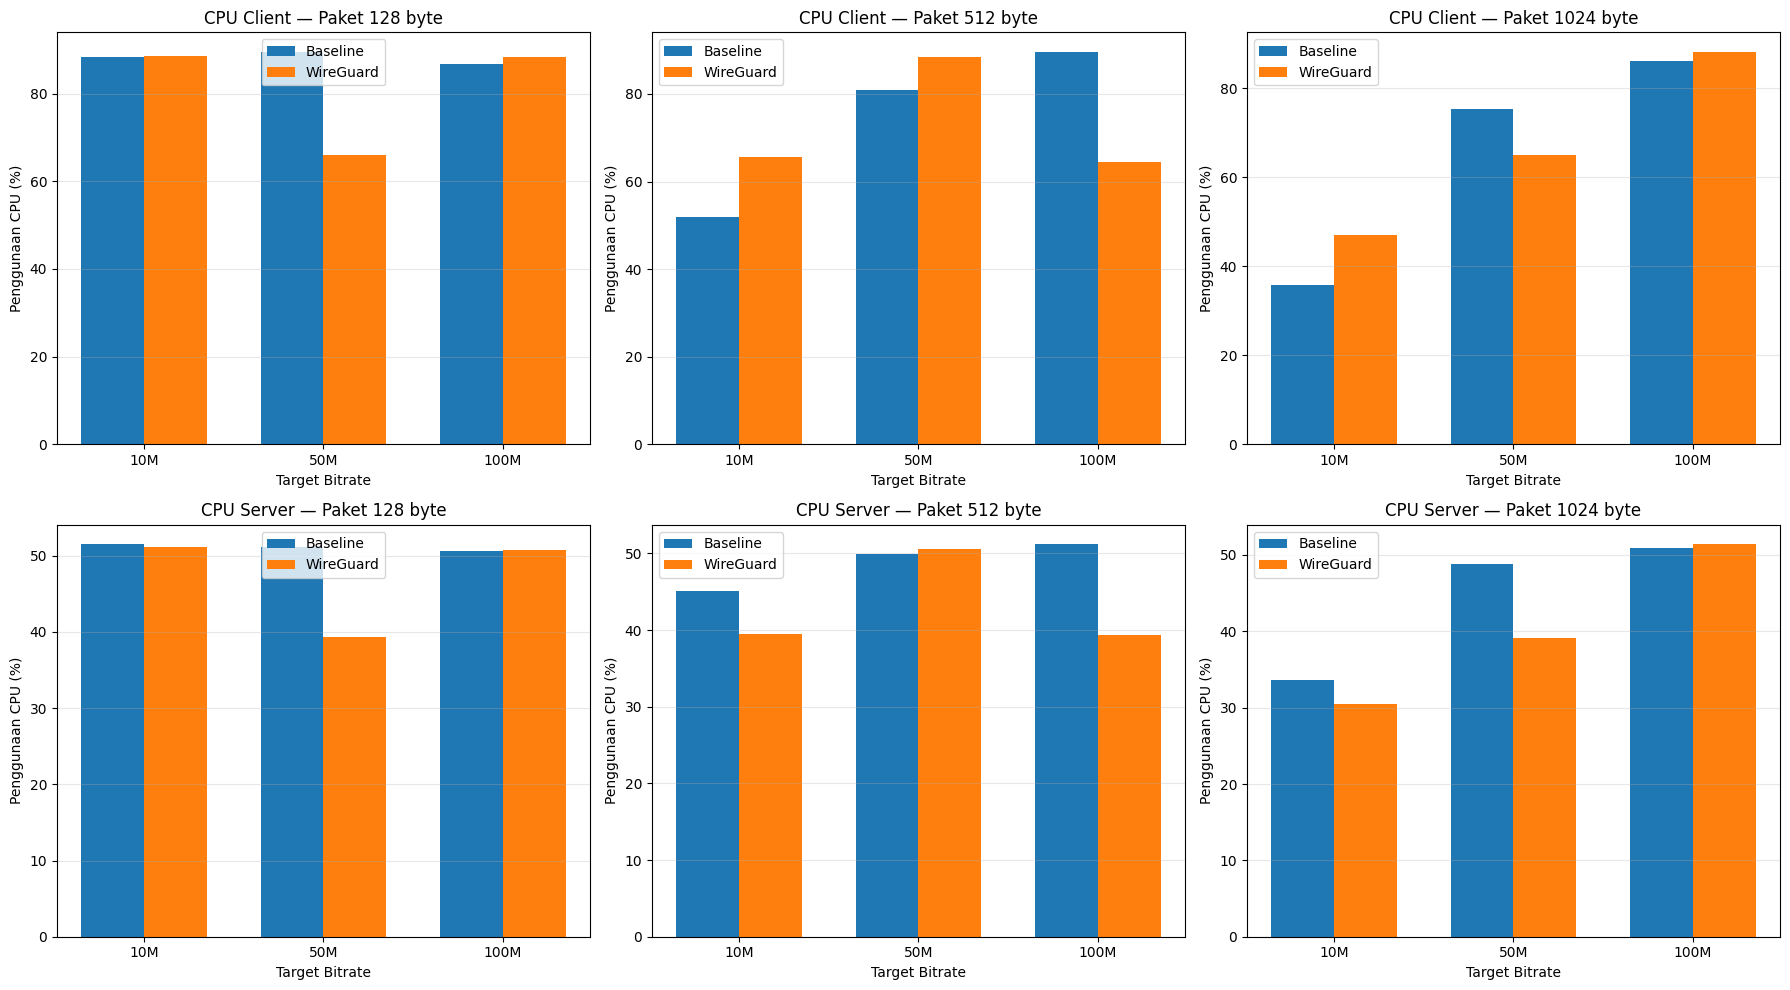

In [21]:
import matplotlib.pyplot as plt

cpu_comparison = (
    df_valid
    .groupby(
        ["packet_size_bytes", "target_rate", "condition"]
    )[["cpu_client_percent", "cpu_server_percent"]]
    .mean()
    .reset_index()
)

rate_order = {"10M": 10, "50M": 50, "100M": 100}
packet_sizes = [128, 512, 1024]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, size in enumerate(packet_sizes):
    data = cpu_comparison[
        cpu_comparison["packet_size_bytes"] == size
    ].copy()

    data = data.sort_values(
        "target_rate",
        key=lambda values: values.map(rate_order)
    )

    x = list(range(len(data[data["condition"] == "BASELINE"])))
    width = 0.35

    for metric, title in [
        (0, "cpu_client_percent", "CPU Client"),
        (1, "cpu_server_percent", "CPU Server")
    ]:
        baseline = (
            data[data["condition"] == "BASELINE"]
            .set_index("target_rate")[metric]
        )
        wireguard = (
            data[data["condition"] == "WIREGUARD"]
            .set_index("target_rate")[metric]
        )

        rates = sorted(
            baseline.index,
            key=lambda rate: rate_order[rate]
        )

        baseline_values = baseline.loc[rates].values
        wireguard_values = wireguard.loc[rates].values

        axes[row, col].bar(
            [i - width / 2 for i in x],
            baseline_values,
            width,
            label="Baseline"
        )
        axes[row, col].bar(
            [i + width / 2 for i in x],
            wireguard_values,
            width,
            label="WireGuard"
        )

        axes[row, col].set_xticks(x)
        axes[row, col].set_xticklabels(rates)
        axes[row, col].set_title(f"{title} — Paket {size} byte")
        axes[row, col].set_xlabel("Target Bitrate")
        axes[row, col].set_ylabel("Penggunaan CPU (%)")
        axes[row, col].grid(axis="y", alpha=0.3)
        axes[row, col].legend()

        plt.tight_layout()
        plt.show()


## validasi

In [22]:
# Periksa status pengujian dan jumlah data
print("Jumlah baris:", len(df_valid))

print("\nJumlah pengujian per kondisi:")
display(
    df_valid.groupby(["condition", "source"]).size()
)

print("\nJumlah nilai kosong:")
display(
    df_valid[
        [
            "throughput_mbps",
            "latency_ms",
            "jitter_ms",
            "packet_loss_percent",
            "cpu_client_percent",
            "cpu_server_percent"
        ]
    ].isna().sum()
)

print("\nStatistik latency dan jitter:")
display(
    df_valid.groupby("condition")[
        ["latency_ms", "jitter_ms"]
    ].agg(["mean", "std", "min", "max"]).round(4)
)

Jumlah baris: 90

Jumlah pengujian per kondisi:


condition  source  
BASELINE   original    44
           retest       1
WIREGUARD  original    45
dtype: int64


Jumlah nilai kosong:


throughput_mbps        0
latency_ms             0
jitter_ms              0
packet_loss_percent    0
cpu_client_percent     0
cpu_server_percent     0
dtype: int64


Statistik latency dan jitter:


latency_ms                             jitter_ms                  \
                mean       std     min       max      mean      std    min   
condition                                                                    
BASELINE      1.4387    0.4171  1.2349    4.0769    0.2350   0.0973  0.151   
WIREGUARD   165.4022  119.6372  3.0340  328.0986    9.0071  17.4422  0.142   

                   
              max  
condition          
BASELINE    0.631  
WIREGUARD  62.361

In [23]:
# Tampilkan pengujian WireGuard dengan latency tertinggi
wg_latency_extreme = (
    df_valid[df_valid["condition"] == "WIREGUARD"]
    .sort_values("latency_ms", ascending=False)
    [
        [
            "experiment_id",
            "packet_size_bytes",
            "target_rate",
            "repeat",
            "source",
            "latency_ms",
            "jitter_ms",
            "throughput_mbps",
            "packet_loss_percent"
        ]
    ]
    .head(10)
)

display(wg_latency_extreme)

,experiment_id,packet_size_bytes,target_rate,repeat,source,latency_ms,jitter_ms,throughput_mbps,packet_loss_percent
55,3_512bytes_100mbps_WIREGUARD_repeat1,512,100M,1,original,328.0986,0.662,4.76,0.0
56,3_512bytes_100mbps_WIREGUARD_repeat2,512,100M,2,original,327.7051,0.803,4.76,0.0
58,3_512bytes_100mbps_WIREGUARD_repeat4,512,100M,4,original,326.9955,0.548,4.76,0.0
59,3_512bytes_100mbps_WIREGUARD_repeat5,512,100M,5,original,325.4119,0.645,4.82,0.0
35,3_512bytes_10mbps_WIREGUARD_repeat1,512,10M,1,original,325.2692,0.872,4.78,0.0
57,3_512bytes_100mbps_WIREGUARD_repeat3,512,100M,3,original,322.9327,0.747,4.82,0.0
16,3_128bytes_50mbps_WIREGUARD_repeat2,128,50M,2,original,320.2600,0.527,1.22,0.0
36,3_512bytes_10mbps_WIREGUARD_repeat2,512,10M,2,original,319.1489,0.804,4.86,0.0
15,3_128bytes_50mbps_WIREGUARD_repeat1,128,50M,1,original,318.8807,0.689,1.22,0.0
39,3_512bytes_10mbps_WIREGUARD_repeat5,512,10M,5,original,318.5764,0.690,4.87,0.0
